In [18]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from scipy import stats
import pickle

from notebooks.imports import *

### Config

In [20]:
import warnings

warnings.filterwarnings("ignore")
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

me_type = "global"

### Load and Preprocess data

In [21]:
with open(Path(processed_dir, f"motion_energies_normalized/me_{me_type}.pkl"), "rb") as f:
    motion_energy_dict = pickle.load(f)

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
print(len(motion_energy_dict))
data

25508


,agg_code,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,stimulus_seed,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,pulse_type
0,DBM12_6_1_1,32,uw,DBM12,6_1,1,0,False,100,1.0,0,0.810402,0.0,NaN,0.626644,25.0,0.0,4.245489,915716,False,0.416750,0.066680,100.0,0
1,DBM12_6_1_2,32,uw,DBM12,6_1,2,0,False,100,1.0,1,1.197263,1.0,1.5,0.546771,25.0,0.0,0.500000,830639,False,0.050010,0.066680,100.0,0
2,DBM12_6_1_3,32,uw,DBM12,6_1,3,0,False,-100,-1.0,0,0.459420,1.0,1.5,0.889096,25.0,0.0,0.500000,14826,False,0.416750,0.066680,-100.0,0
3,DBM12_6_1_4,32,uw,DBM12,6_1,4,0,False,-100,-1.0,0,0.446027,1.0,1.5,0.515926,25.0,0.0,0.500000,921577,False,0.050010,0.066680,-100.0,0
4,DBM12_6_1_5,32,uw,DBM12,6_1,5,0,False,-100,-1.0,0,0.398053,1.0,1.5,0.540356,25.0,0.0,0.500000,111085,False,0.416750,0.066680,-100.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25503,PSUIM7_9_1_613,290,ucla,PSUIM7,9_1,613,0,False,9,1.0,1,1.899836,1.0,1.5,1.000000,60.0,0.5,0.250000,613,False,NaN,NaN,NaN,0
25504,PSUIM7_9_1_615,290,ucla,PSUIM7,9_1,615,0,False,100,1.0,1,3.865409,1.0,1.5,1.000000,60.0,0.5,0.250000,615,False,NaN,NaN,NaN,0
25505,PSUIM7_9_1_617,290,ucla,PSUIM7,9_1,617,0,False,18,1.0,0,0.950079,0.0,0.0,1.000000,60.0,1.5,0.809093,617,False,NaN,NaN,NaN,0
25506,PSUIM7_9_1_619,290,ucla,PSUIM7,9_1,619,0,False,-36,-1.0,0,1.200340,1.0,1.5,1.000000,60.0,0.5,0.250000,619,True,0.242148,0.050971,-100.0,-2


In [22]:
missing_in_motion_data = set(data.agg_code) - set(motion_energy_dict)
extra_in_motion_data = set(motion_energy_dict) - set(data.agg_code)

assert len(missing_in_motion_data) == 0, f"Missing keys in motion_data_dict: {missing_in_motion_data}"
assert len(extra_in_motion_data) == 0, f"Extra keys in motion_data_dict: {extra_in_motion_data}"

### Utils

In [23]:
# Define mapping from pulse_type to descriptive variable names
pulse_mapping = {
    -3: "late_left_pulse",
    -2: "middle_left_pulse",
    -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse",
    2: "middle_right_pulse",
    3: "late_right_pulse",
}

In [24]:
# Define mapping from pulse_type to descriptive variable names
def get_motion_data(trial_indices, motion_energy_dict):
    # List to store the motion data
    motion_data_array = []

    # Keep track of the max shape of the motion data
    max_shape = (0, 0, 0)  # Initialize with zeros, assuming 3 dimensions (for safety)

    for i in trial_indices:
        try:
            if i in motion_energy_dict.keys():
                motion_data_array.append(motion_energy_dict[i])
                max_shape = tuple(map(max, zip(max_shape, motion_energy_dict[i].shape)))
            else:
                print(f"Warning: Index {i} not found in motion_data_dict.")
        except Exception as e:
            print(f"Error processing index {i}: {e}")

    padded_motion_data = []
    for data in motion_data_array:
        if data.ndim == 1:
            padded_data = np.pad(data, (0, max_shape[0] - data.shape[0]), mode="constant")
        elif data.ndim == 2:
            padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1])], mode="constant")
        elif data.ndim == 3:
            padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1]), (0, max_shape[2] - data.shape[2])], mode="constant")
        else:
            raise ValueError(f"Unexpected number of dimensions in motion data: {data.ndim}")
        padded_motion_data.append(padded_data)

    motion_data_array = np.array(padded_motion_data)
    return motion_data_array

### Code

In [25]:
pulse_type = data.pulse_type.unique()

for pt in sorted(pulse_type):
    print(f"{pt}: {pulse_mapping.get(pt, None)}")

-3: late_left_pulse
-2: middle_left_pulse
-1: early_left_pulse
0: control
1: early_right_pulse
2: middle_right_pulse
3: late_right_pulse


In [26]:
# note indices for each pulse_type and each signed_coherence under each pulse_type
indices = {}
for pt in pulse_type:
    indices[pt] = {}
    for sc in data.signed_coherence.unique():
        indices[pt][sc] = data[(data.pulse_type == pt) & (data.signed_coherence == sc)].agg_code.values

In [27]:
# Initialize pulse_energy dictionary as {pulse_time: {coh: motion_array}}
pulse_energy = {}

# Loop through each pulse type and its corresponding coherences
for pt in pulse_type:
    pulse_time = pulse_mapping.get(pt, None)
    if pulse_time is None:
        print(f"⚠️ Unknown pulse_type {pt}, skipping.")
        continue

    pulse_energy[pulse_time] = {}

    for coh in indices.get(pt, {}):
        motion_energy = get_motion_data(indices[pt][coh], motion_energy_dict)

        if motion_energy.size > 0:
            pulse_energy[pulse_time][coh] = motion_energy
        else:
            print(f"⚠️ Skipping pulse_time {pulse_time}, coherence {coh}: No valid data found")
            continue

⚠️ Skipping pulse_time middle_right_pulse, coherence 100: No valid data found
⚠️ Skipping pulse_time late_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time early_right_pulse, coherence 100: No valid data found
⚠️ Skipping pulse_time early_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time middle_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time late_right_pulse, coherence 100: No valid data found


In [28]:
def plot_pulse_energy(pulse_energy, pulse_type, coh, ax=None, error="std"):
    try:
        mean = np.nanmean(pulse_energy[pulse_type][coh], axis=0)
        std = np.nanstd(pulse_energy[pulse_type][coh], axis=0)
        sem = stats.sem(pulse_energy[pulse_type][coh], axis=0, nan_policy="omit")
        x = np.arange(mean.shape[0])

        if ax is None:
            plt.plot(x, mean, label=pulse_type)
            if error == "std":
                plt.fill_between(x, mean - std, mean + std, alpha=0.3)
            elif error == "sem":
                print("Using SEM for error bars")
                plt.fill_between(x, mean - sem, mean + sem, alpha=0.3)
        else:
            ax.plot(x, mean, label=pulse_type)
            if error == "std":
                ax.fill_between(x, mean - std, mean + std, alpha=0.3)
            elif error == "sem":
                ax.fill_between(x, mean - sem, mean + sem, alpha=0.3)

    except KeyError:
        print(f"⚠️ {pulse_type} with coherence {coh} not found.")


def plot_all_pulses(ax, pulse_energy, coh, title, error: Optional[str] = None):
    pulses: list[str] = ["early_left_pulse", "middle_left_pulse", "late_left_pulse", "early_right_pulse", "middle_right_pulse", "late_right_pulse"]
    for pulse in pulses:
        plot_pulse_energy(pulse_energy, pulse, coh, ax=ax, error=error)
    ax.set_title(title, fontsize=16)
    ax.set_xlim([0, 60])
    xticks = np.arange(0, 61, 10)
    xticks_msec = np.round(xticks * 1000 / 60)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks_msec.astype(int))
    ax.set_xlabel("Time (msec)")
    ax.set_ylabel("Motion Energy (equiv. % coherence)")
    ax.legend()

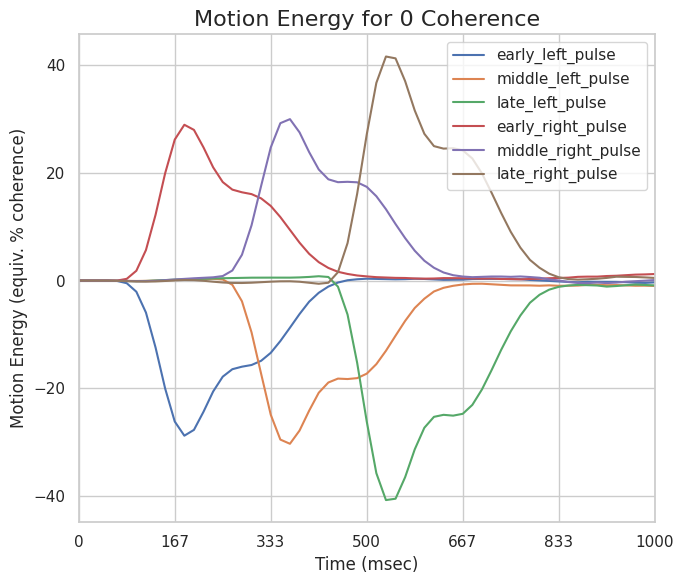

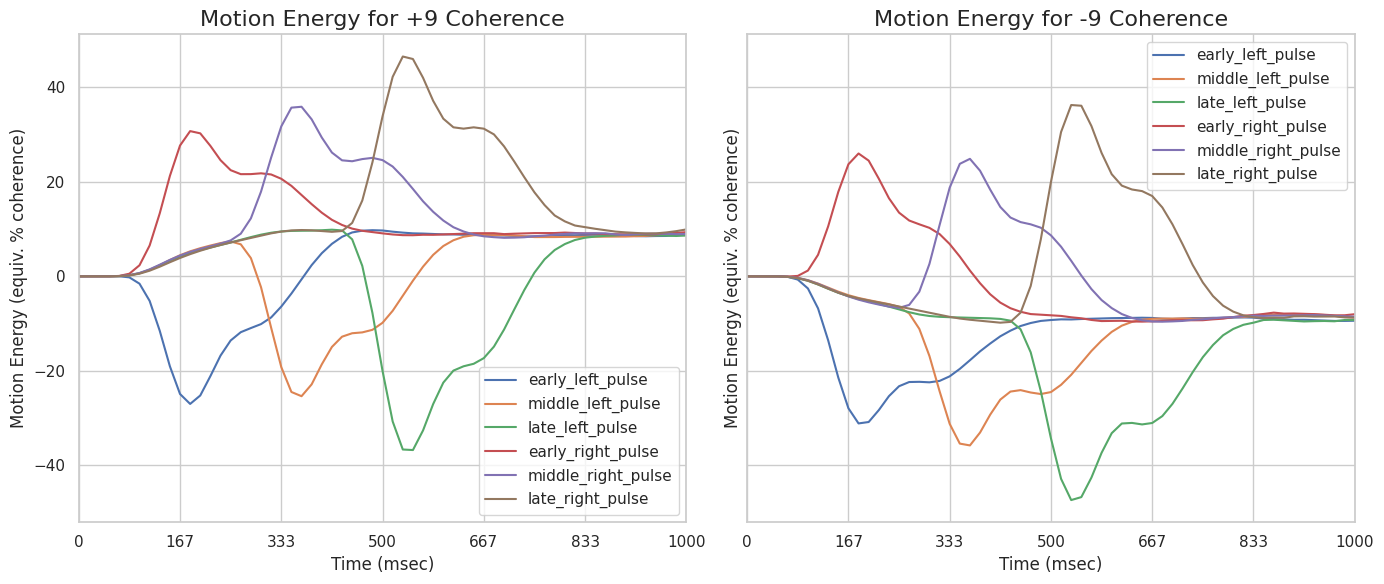

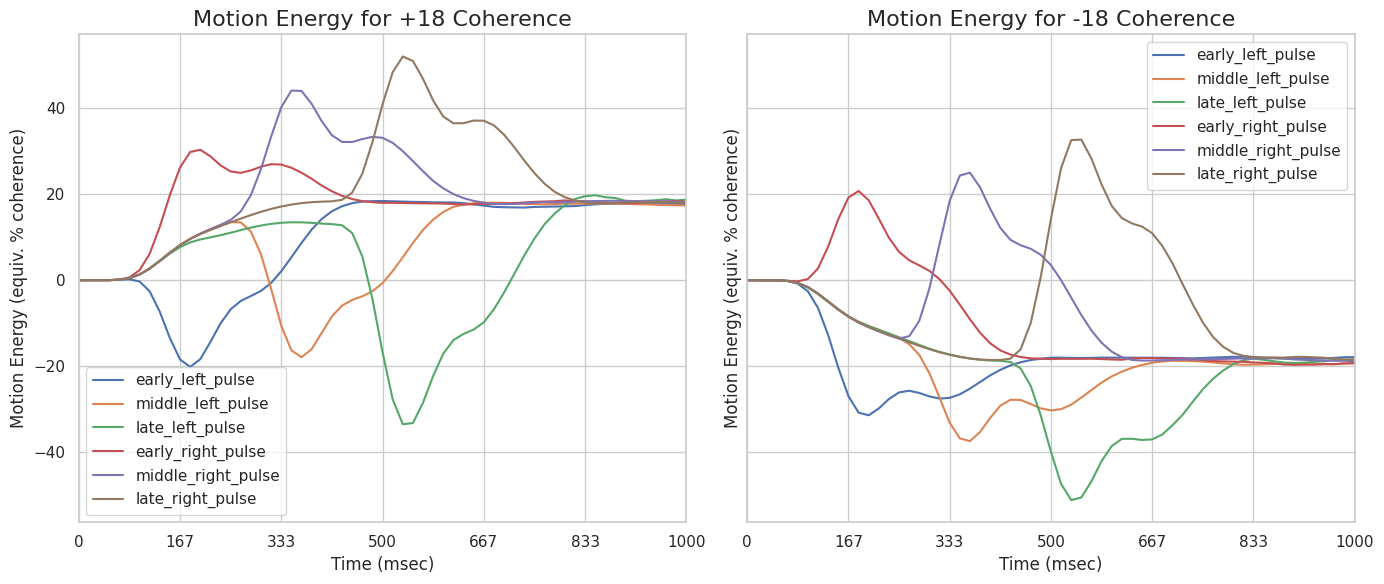

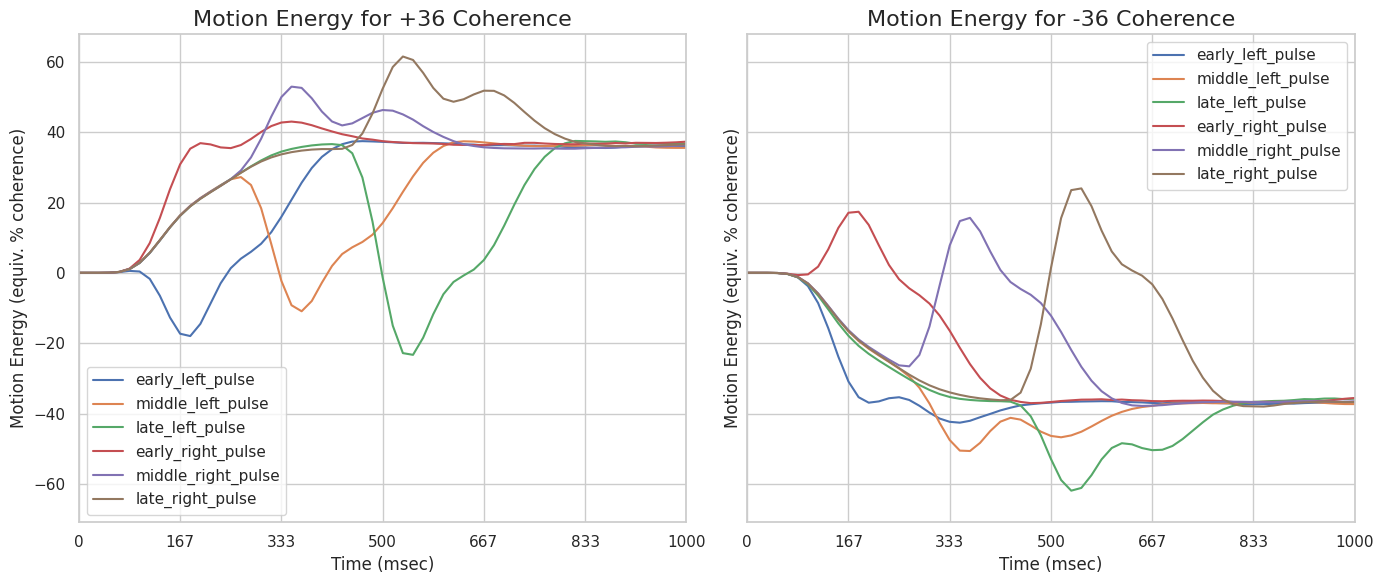

⚠️ early_right_pulse with coherence 100 not found.
⚠️ middle_right_pulse with coherence 100 not found.
⚠️ late_right_pulse with coherence 100 not found.
⚠️ early_left_pulse with coherence -100 not found.
⚠️ middle_left_pulse with coherence -100 not found.
⚠️ late_left_pulse with coherence -100 not found.


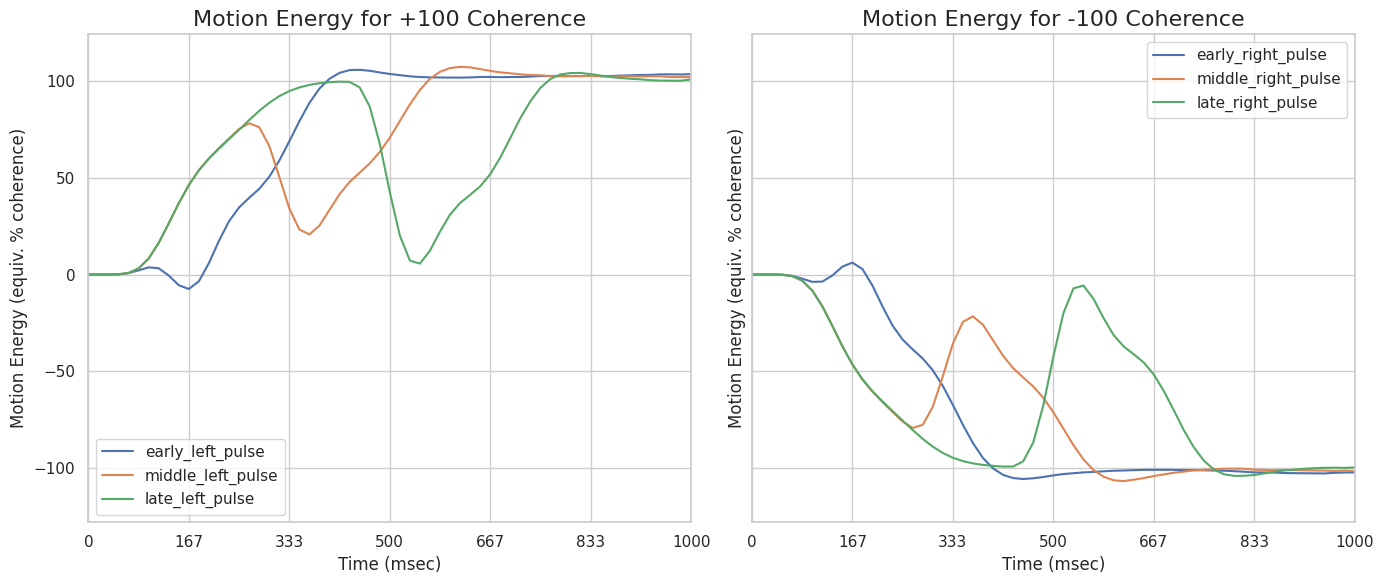

In [29]:
unique_coherences = np.unique(np.abs(data.signed_coherence))
for coh in unique_coherences:
    if coh != 0:
        fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
        plot_all_pulses(axs[0], pulse_energy, +coh, f"Motion Energy for +{coh} Coherence")
        plot_all_pulses(axs[1], pulse_energy, -coh, f"Motion Energy for -{coh} Coherence")
        plt.tight_layout()
        plt.show()
    else:
        fig, ax = plt.subplots(figsize=(7, 6))
        plot_all_pulses(ax, pulse_energy, 0, f"Motion Energy for {coh} Coherence")
        plt.tight_layout()
        plt.show()

---
---

⚠️ early_right_pulse with coherence 100 not found.
⚠️ middle_right_pulse with coherence 100 not found.
⚠️ late_right_pulse with coherence 100 not found.
⚠️ early_left_pulse with coherence -100 not found.
⚠️ middle_left_pulse with coherence -100 not found.
⚠️ late_left_pulse with coherence -100 not found.


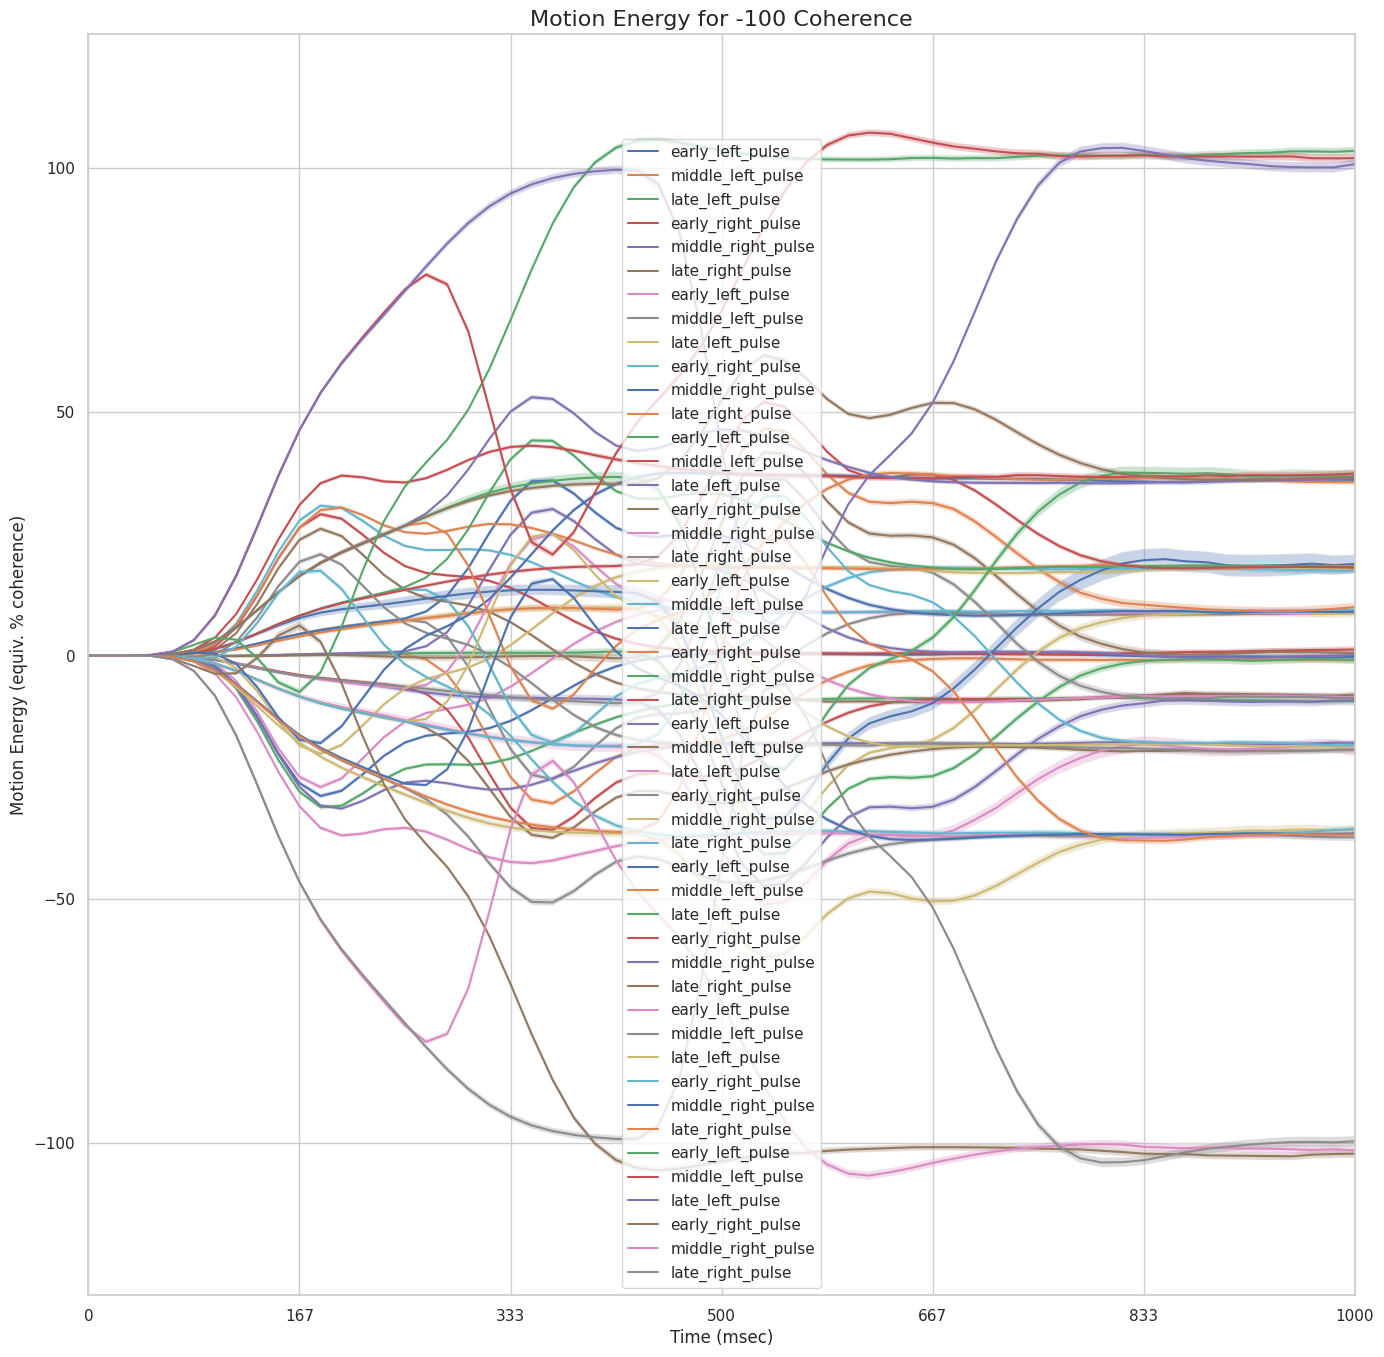

In [30]:
unique_coherences = np.unique(np.abs(data.signed_coherence))

fig, ax = plt.subplots(1, 1, figsize=(14, 14), sharey=True)
for coh in unique_coherences:
    if coh != 0:
        plot_all_pulses(ax, pulse_energy, +coh, f"Motion Energy for +{coh} Coherence", error="sem")
        plot_all_pulses(ax, pulse_energy, -coh, f"Motion Energy for -{coh} Coherence", error="sem")
    else:
        plot_all_pulses(ax, pulse_energy, 0, f"Motion Energy for {coh} Coherence", error="sem")
plt.tight_layout()
plt.show()

⚠️ early_right_pulse with coherence 100 not found.
⚠️ middle_right_pulse with coherence 100 not found.
⚠️ late_right_pulse with coherence 100 not found.
⚠️ early_left_pulse with coherence -100 not found.
⚠️ middle_left_pulse with coherence -100 not found.
⚠️ late_left_pulse with coherence -100 not found.


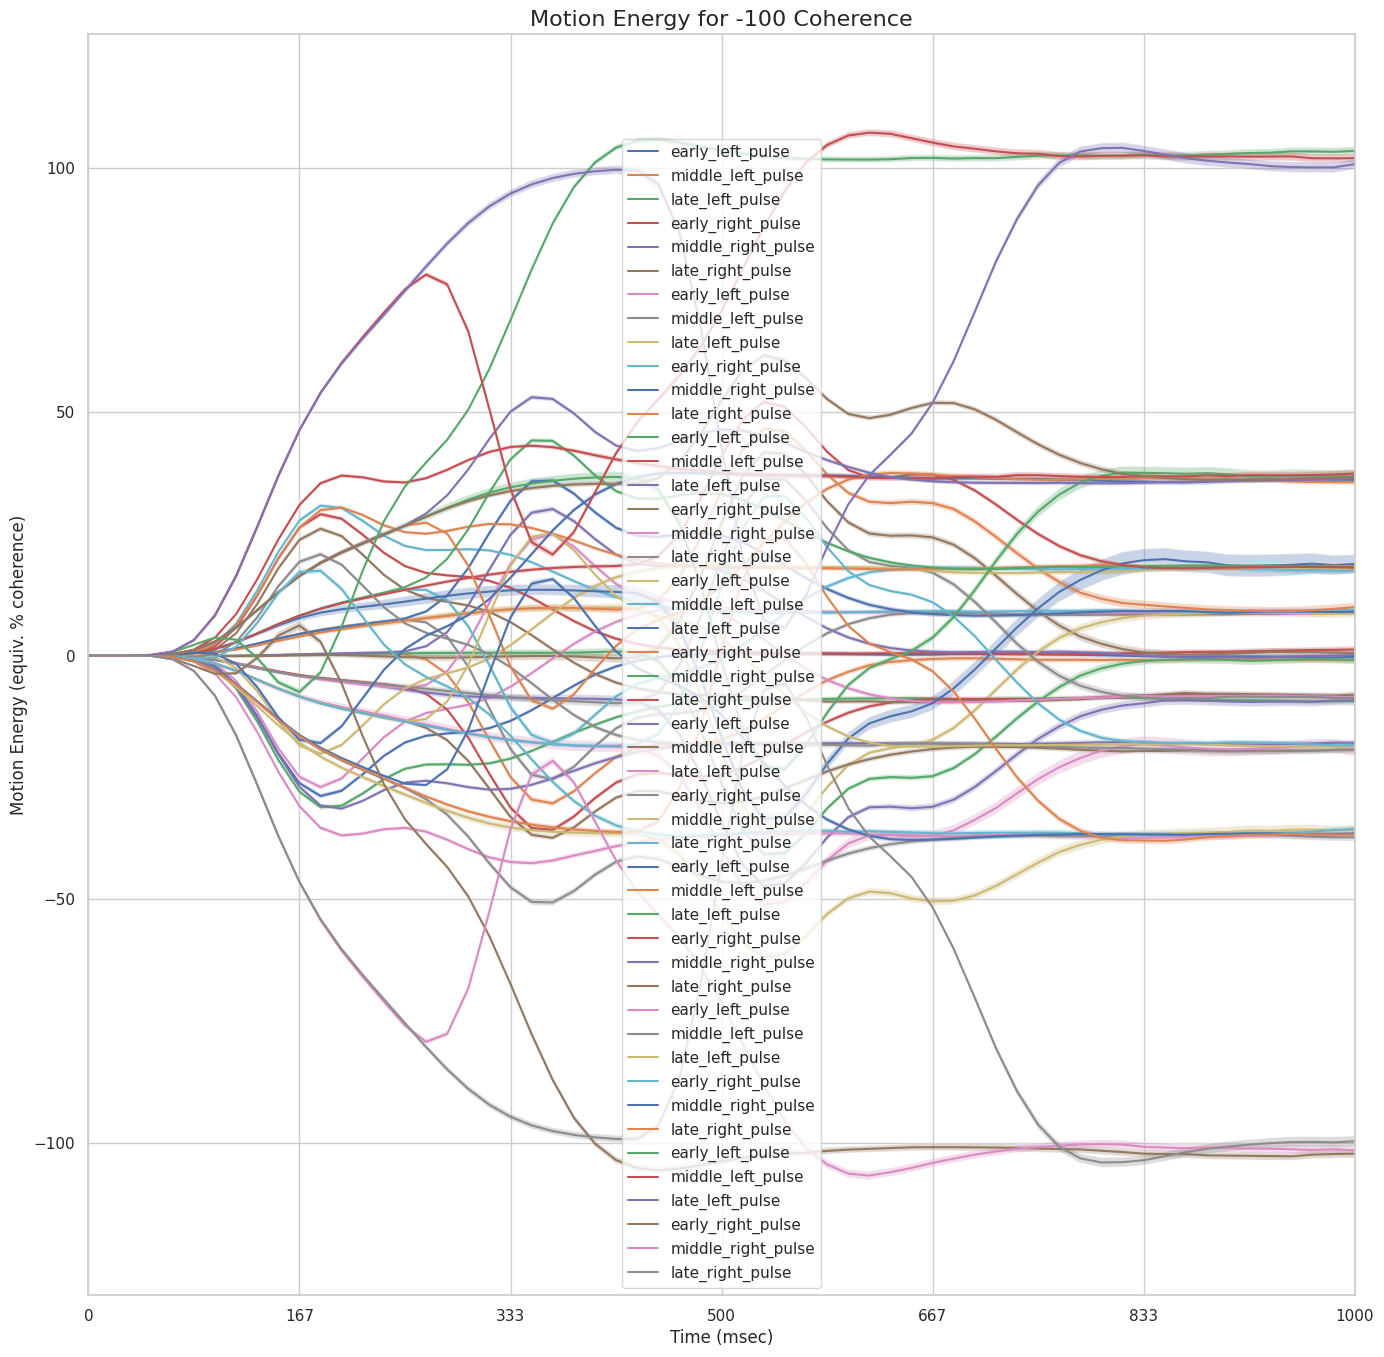

In [31]:
unique_coherences = np.unique(np.abs(data.signed_coherence))

fig, ax = plt.subplots(1, 1, figsize=(14, 14), sharey=True)
for coh in unique_coherences:
    if coh != 0:
        plot_all_pulses(ax, pulse_energy, +coh, f"Motion Energy for +{coh} Coherence", error="sem")
        plot_all_pulses(ax, pulse_energy, -coh, f"Motion Energy for -{coh} Coherence", error="sem")
    else:
        plot_all_pulses(ax, pulse_energy, 0, f"Motion Energy for {coh} Coherence", error="sem")
plt.tight_layout()
plt.show()

ME vs Coherences

In [32]:
pulse_energy.keys()

dict_keys(['control', 'middle_right_pulse', 'late_left_pulse', 'early_right_pulse', 'early_left_pulse', 'middle_left_pulse', 'late_right_pulse'])

In [33]:
unique_coherences

array([  0,   9,  18,  36, 100])

In [34]:
np.nanmean(pulse_energy[pulse_type][coh], axis=0)[100], np.nanmean(pulse_energy[pulse_type][coh][:, 100:120])

TypeError: unhashable type: 'numpy.ndarray'

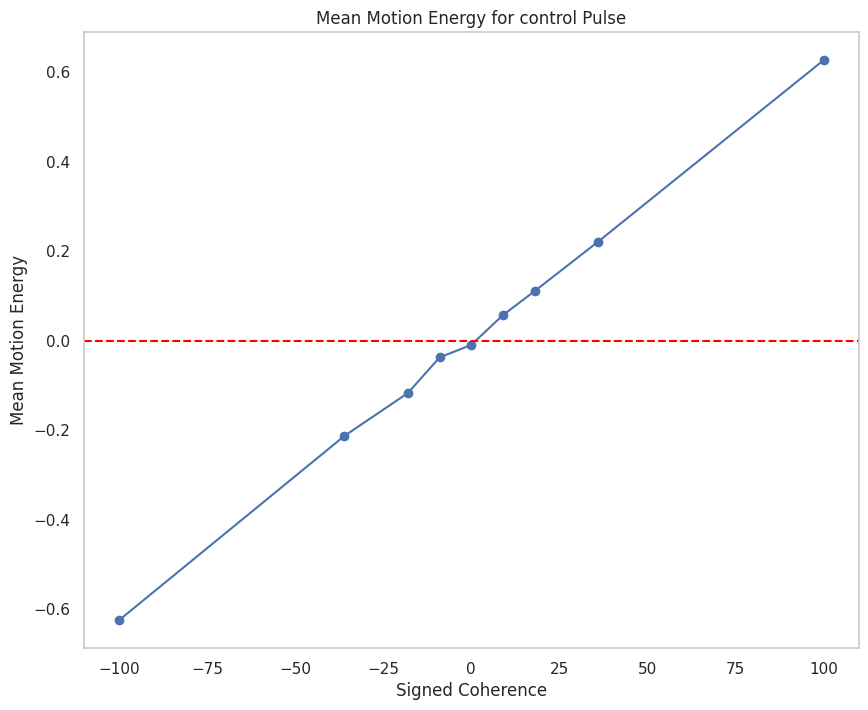

In [ ]:
pulse_type = "control"
coh_list, mean_me = [], []
for coh in np.sort(data.signed_coherence.unique()):
    mean_me.append(np.nanmean(pulse_energy[pulse_type][coh][:, 80:120]))
    coh_list.append(coh)

plt.figure(figsize=(10, 8))
plt.plot(coh_list, mean_me, marker="o")
plt.title(f"Mean Motion Energy for {pulse_type} Pulse")
plt.xlabel("Signed Coherence")
plt.ylabel("Mean Motion Energy (equiv. % coherence)")
plt.axhline(0, color="red", linestyle="--")
plt.grid()
plt.show()